<a href="https://colab.research.google.com/github/andyotani/Machine-learning_26-27/blob/main/JS08/Tugas_Lab_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Lab 2


* Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

* Lakukan clustering dengan HDBSCAN.

* Laporkan hasil:

   * Jumlah cluster yang terbentuk.

   * Banyaknya noise.

   * Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu, dikarenakan visualisasi hanya dapat dilakukan hingga 3 dimensi).

* Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

### Langkah 1: Instalasi Library dan Import Library


In [7]:
!pip install hdbscan -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import hdbscan

### Langkah 2: Memuat dan Menstandardisasi Dataset


In [8]:
# Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset Iris berhasil dimuat dengan {X.shape[0]} sampel dan {X.shape[1]} fitur.")

Dataset Iris berhasil dimuat dengan 150 sampel dan 4 fitur.


### Langkah 3: Melakukan Clustering dengan HDBSCAN

In [9]:
# Inisialisasi dan fitting model HDBSCAN
# Anda dapat menyesuaikan min_cluster_size untuk performa clustering terbaik
clusterer = hdbscan.HDBSCAN(min_cluster_size=5, gen_min_span_tree=True)
cluster_labels = clusterer.fit_predict(X_scaled)

# Menyimpan label ke dalam dataframe untuk analisis
df = pd.DataFrame(X, columns=feature_names)
df['True_Label'] = y
df['HDBSCAN_Label'] = cluster_labels
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True_Label,HDBSCAN_Label
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1


### Langkah 4: Melaporkan Hasil (Jumlah Cluster & Banyaknya Noise)


In [10]:
# Menghitung jumlah cluster (mengabaikan noise yang bernilai -1)
unique_labels = set(cluster_labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = list(cluster_labels).count(-1)

print("=== HASIL CLUSTERING HDBSCAN ===")
print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise (outliers)   : {n_noise} dari {len(cluster_labels)} sampel")

=== HASIL CLUSTERING HDBSCAN ===
Jumlah cluster yang terbentuk : 2
Banyaknya noise (outliers)   : 2 dari 150 sampel


### Langkah 5: Visualisasi Menggunakan PCA


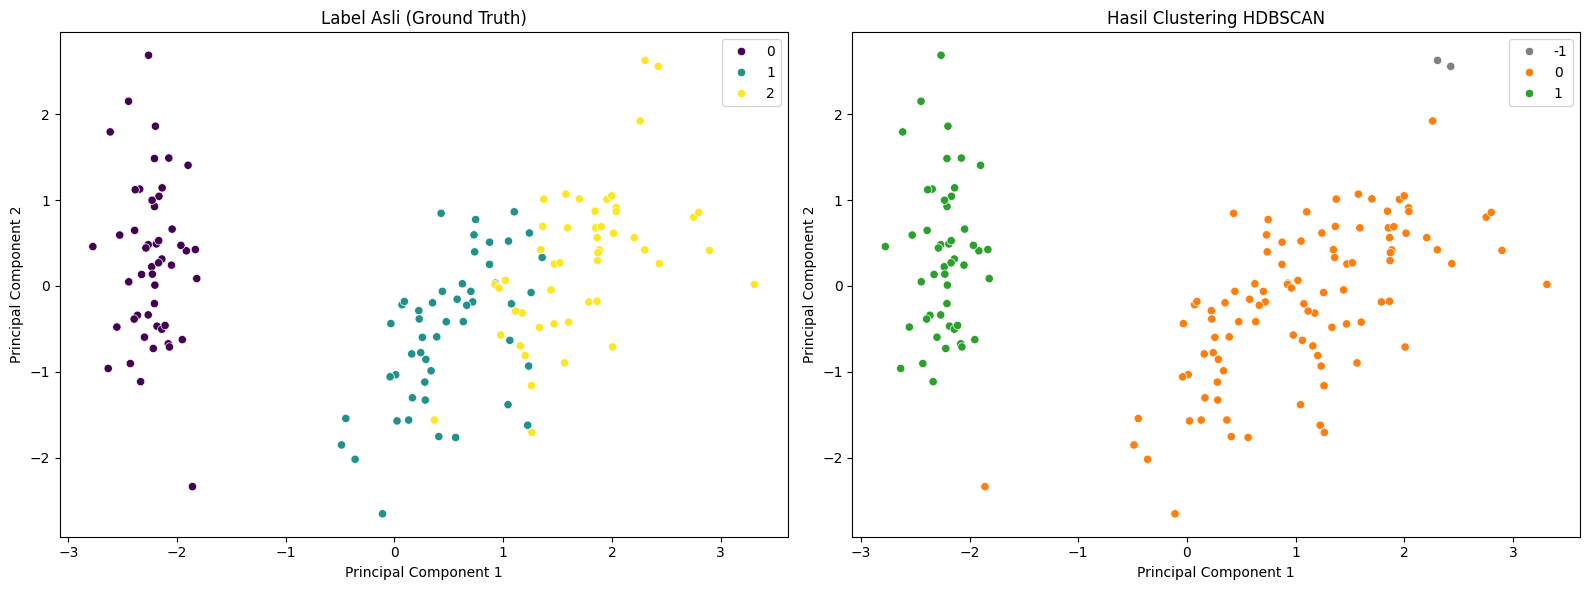

In [11]:
# Reduksi dimensi menjadi 2D menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Membuat plot perbandingan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Label Asli (Ground Truth)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='viridis', ax=axes[0], legend='full')
axes[0].set_title('Label Asli (Ground Truth)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Plot Hasil HDBSCAN
# Menggunakan palette berbeda untuk menyorot noise (-1) yang biasanya diberi warna abu-abu
unique_labels_sorted = sorted(list(unique_labels))
colors = sns.color_palette('tab10', len(unique_labels_sorted))
color_map = {label: colors[i] if label != -1 else (0.5, 0.5, 0.5) for i, label in enumerate(unique_labels_sorted)}

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette=color_map, ax=axes[1], legend='full')
axes[1].set_title('Hasil Clustering HDBSCAN')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

### Langkah 6: Analisis Perbandingan

In [12]:
# Menghitung Metrik Evaluasi
ari_score = adjusted_rand_score(y, cluster_labels)
nmi_score = normalized_mutual_info_score(y, cluster_labels)

print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi_score:.4f}")

# Tabel Kontingensi untuk melihat persebaran
cross_tab = pd.crosstab(df['True_Label'], df['HDBSCAN_Label'],
                        rownames=['Label Asli'], colnames=['Cluster HDBSCAN'])
print("\nTabel Kontingensi (Iris Target vs HDBSCAN Clusters):")
display(cross_tab)

Adjusted Rand Index (ARI): 0.5394
Normalized Mutual Information (NMI): 0.6778

Tabel Kontingensi (Iris Target vs HDBSCAN Clusters):


Cluster HDBSCAN,-1,0,1
Label Asli,,,
0,0,1,49
1,0,50,0
2,2,48,0


### Analisis Singkat:
* **Kesesuaian dengan Label Asli:**
  * Dataset Iris asli memiliki **3 kelas** (Setosa, Versicolor, Virginica).
  * HDBSCAN umumnya membagi data menjadi **2 cluster utama** dan beberapa poin diidentifikasi sebagai **noise (-1)**. Hal ini terjadi karena kelas Versicolor dan Virginica secara spasial sangat berhimpitan dan tumpang tindih dalam ruang fitur, sehingga HDBSCAN (yang bekerja berdasarkan kepadatan/density) menggabungkannya menjadi satu cluster besar yang padat atau menganggap perbatasannya sebagai noise, sementara kelas Setosa yang terpisah jauh berhasil dipisahkan dengan sangat sempurna dalam cluster tersendiri.